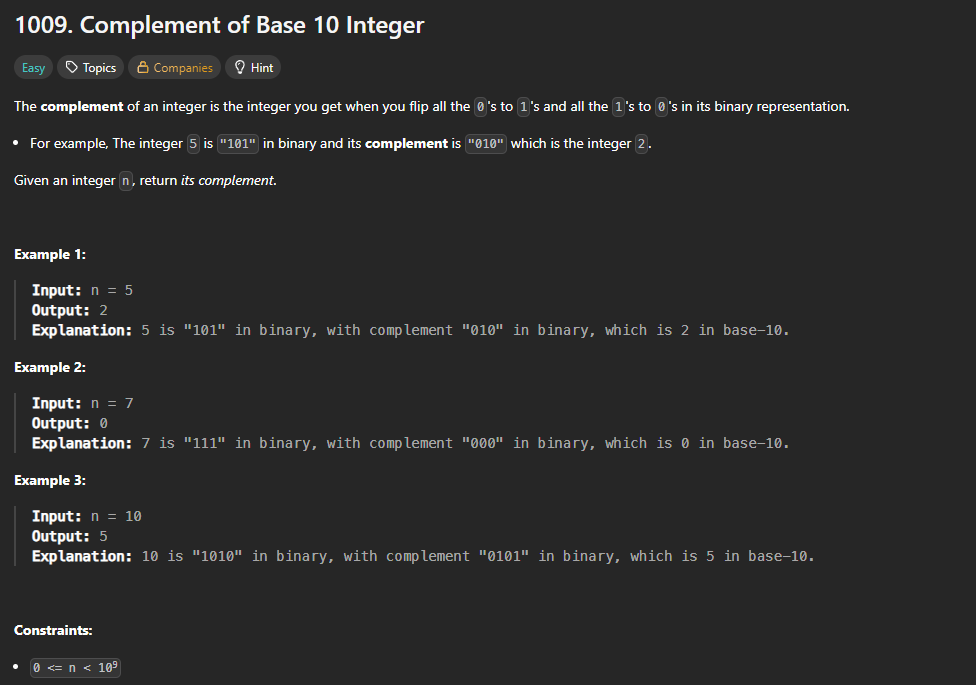

### Detailed Code Explanation & Logical Reasoning

This solution finds the **bitwise complement** of a given base-10 integer $N$. The bitwise complement of a number is the number you get when you flip all the `1`s to `0`s and all the `0`s to `1`s in its binary representation (ignoring leading zeros).

#### 1. Handling the Base Case (`n == 0`)
```python
if n == 0:
    return 1
```
* **Reasoning:** The binary representation of `0` is simply `0`. Flipping its only bit gives `1`. Handling this upfront is necessary because the mathematical approach for calculating the bit-length of `0` returns `0`, which would skew our mask calculations.

#### 2. Calculating the Bit Length
```python
bits = n.bit_length()
```
* **Reasoning:** We need to know exactly how many bits are required to represent $N$ in binary without leading zeros. For example:
  * `5` in binary is `101` (3 bits).
  * `10` in binary is `1010` (4 bits).
* The standard bitwise NOT operator (`~n`) in Python operations uses arbitrary-precision integers, which would flip the infinite leading sign bits, returning a negative number (e.g., `~5` becomes `-6`). Calculating the precise bit length helps us create a boundary mask to avoid this.

#### 3. Creating the Bitmask
```python
mask = (1 << bits) - 1
```
* **Reasoning:** To flip only the significant bits of $N$, we create a mask of the same bit length consisting entirely of `1`s.
  * Shifting `1` to the left by `bits` positions (`1 << bits`) creates a binary number with a `1` followed by `bits` number of `0`s (e.g., for `bits = 3`, `1 << 3` gives `1000` in binary, which is `8`).
  * Subtracting `1` from this value turns all those trailing `0`s into `1`s, and the leading `1` becomes `0`. For example, `8 - 1 = 7`, which is `111` in binary.

#### 4. Applying the XOR Operator
```python
return n ^ mask
```
* **Reasoning:** The XOR (`^`) operator compares two bits and returns `1` if the bits are different, and `0` if they are the same.
* When you XOR any bit $B$ with `1`:
  * `0 ^ 1 = 1`
  * `1 ^ 1 = 0`
* Therefore, XORing $N$ with a mask of all `1`s flips every single bit in $N$.

---

### Step-by-Step Trace Example ($N = 5$):
1. **Base Case:** $5 \neq 0$, proceed.
2. **Bit Length:** `5` is `101` in binary $\rightarrow$ `bits = 3`.
3. **Mask Generation:**
   * `1 << 3` $\rightarrow$ `1000` in binary.
   * `1000 - 1` $\rightarrow$ `0111` in binary (`mask = 7`).
4. **XOR Operation:**
   * `5 ^ 7` $\rightarrow$ `101 ^ 111` = `010` in binary (which is `2` in base-10).
5. **Result:** Returns `2`.

In [4]:
class Solution:
    def bitwiseComplement(self, n: int) -> int:
      if n == 0:
        return 1

      bits = n.bit_length()

      mask = (1 << bits) - 1

      return n ^ mask

s = Solution()

In [5]:
print(s.bitwiseComplement(n = 5))

2


In [6]:
print(s.bitwiseComplement(n = 10))

5
